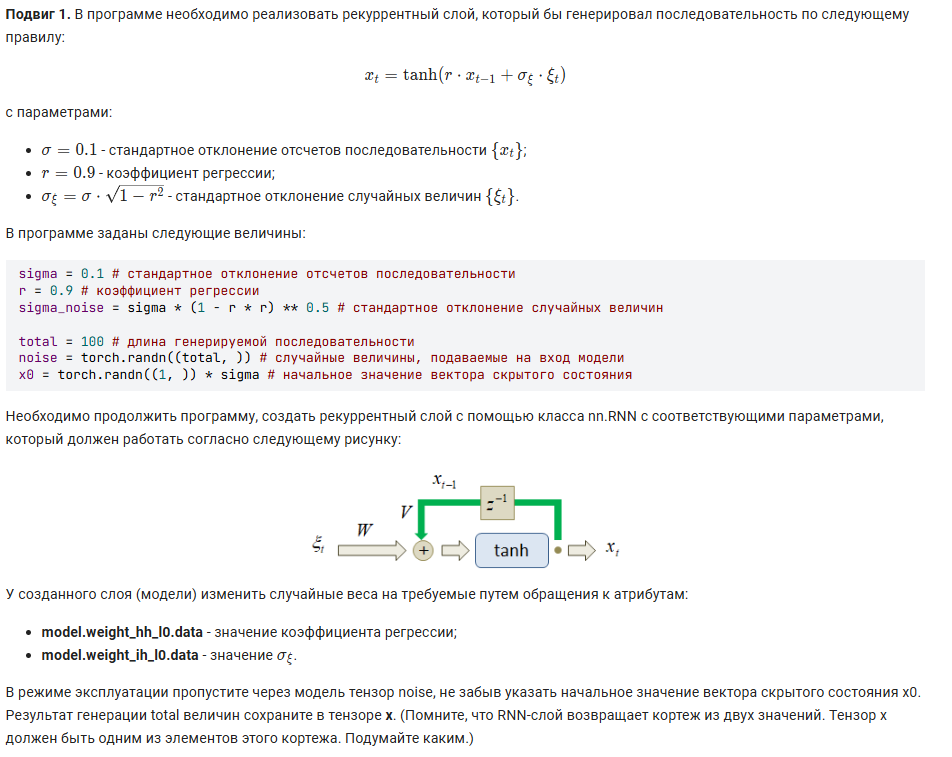

In [79]:
import torch
import torch.nn as nn

sigma = 0.1 # стандартное отклонение отсчетов последовательности
r = 0.9 # коэффициент регрессии
sigma_noise = sigma * (1 - r * r) ** 0.5 # стандартное отклонение случайных величин

total = 100 # длина генерируемой последовательности
noise = torch.randn((total, )) # случайные величины, подаваемые на вход модели
x0 = torch.randn((1, )) * sigma # начальное значение вектора скрытого состояния

# здесь продолжайте программу

model = nn.RNN(input_size=1, hidden_size=1, bias=False, batch_first=True)
model.weight_hh_l0.data = torch.tensor(r, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
model.weight_ih_l0.data = torch.tensor(sigma_noise, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

model.eval()
x, h = model(noise.view(1, total, 1), x0.view(1, 1, 1))

In [55]:
model.weight_ih_l0.data

tensor([[0.0436]])

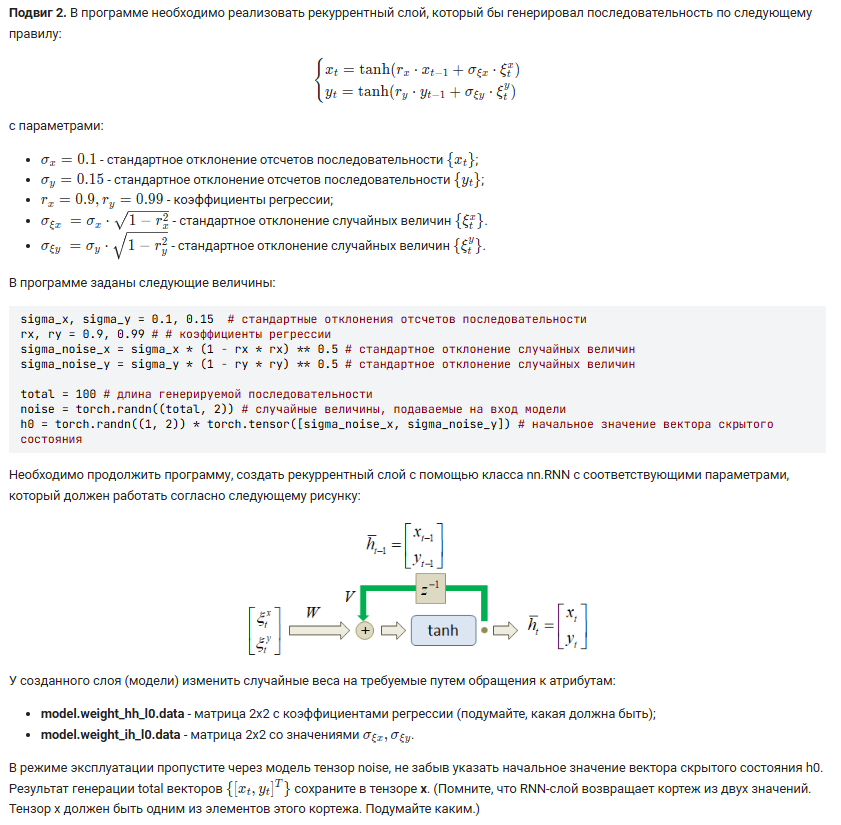

In [93]:
'''Просидел с этими задачками два дня, и, на мой взгляд, было бы нагляднее реализовать матричное умножение рекуррентного блока вручную, 
а в задачах дать разные размеры входной последовательности и вектора скрытого состояния. 

Так как r*x это нифига не матрица_весов@входной_вектор. Это входной_вектор@матрица_весов.Т!

Вот выдержка из help(nn.RNN):

h_t = \tanh(x_t W_{ih}^T + b_{ih} + h_{t-1}W_{hh}^T + b_{hh})
Перепишем сумму матричных произведений в скобках попроще: x@W.T + h@V.T

Стало быть, если мы подаем на вход в блок последовательность размерностью (batch_size, seq_length, dim_size), 
то на каждом шаге RNN на вход будет поступать входной тезнор размерностью  [batch_size, dim_size]. 
Он умножается на W.T. Значит размерность W.T должна быть [dim_size, hidden_size], 
так как далее тензор ни на что не умножается (не имеет возможности изменить форму), 
а в результате умножения мы должны получить вектор скрытого состония. Итак, размерность x@W.T = [batch_size, hidden_size].

Далее этот тензор мы должны умножить на что-то, чтобы иметь возможность сложить с тензором такой же размерности. 
Очевидно, на квадратную матрицу, так как [batch_size, hidden_size]@[hidden_size, hidden_size]= [batch_size, hidden_size]

Отсюда вывод, что размерности для W и V следующие:

W: [hidden_size, dim_size] (ранее я приводил сразу её траспонированную форму)

V: [hidden_size, hidden_size]'''

import torch
import torch.nn as nn

sigma_x, sigma_y = 0.1, 0.15  # стандартные отклонения отсчетов последовательности
rx, ry = 0.9, 0.99 # # коэффициенты регрессии
sigma_noise_x = sigma_x * (1 - rx * rx) ** 0.5 # стандартное отклонение случайных величин
sigma_noise_y = sigma_y * (1 - ry * ry) ** 0.5 # стандартное отклонение случайных величин

total = 100 # длина генерируемой последовательности
noise = torch.randn((total, 2)) # случайные величины, подаваемые на вход модели
h0 = torch.randn((1, 2)) * torch.tensor([sigma_noise_x, sigma_noise_y]) # начальное значение вектора скрытого состояния

# здесь продолжайте программу
model = nn.RNN(input_size=2, hidden_size=2, bias=False, batch_first=True)

# значение коэффициента регрессии (V)
model.weight_hh_l0.data = torch.tensor([[rx, 0], [0, ry]], dtype=torch.float32)

# значение сигма_эпселон (W)
model.weight_ih_l0.data = torch.tensor([[sigma_noise_x, 0], [0, sigma_noise_y]], dtype=torch.float32)

model.eval()
y, h = model(noise.view(1, total, 2), h0.unsqueeze(0))
print(h.shape)

torch.Size([1, 1, 2])


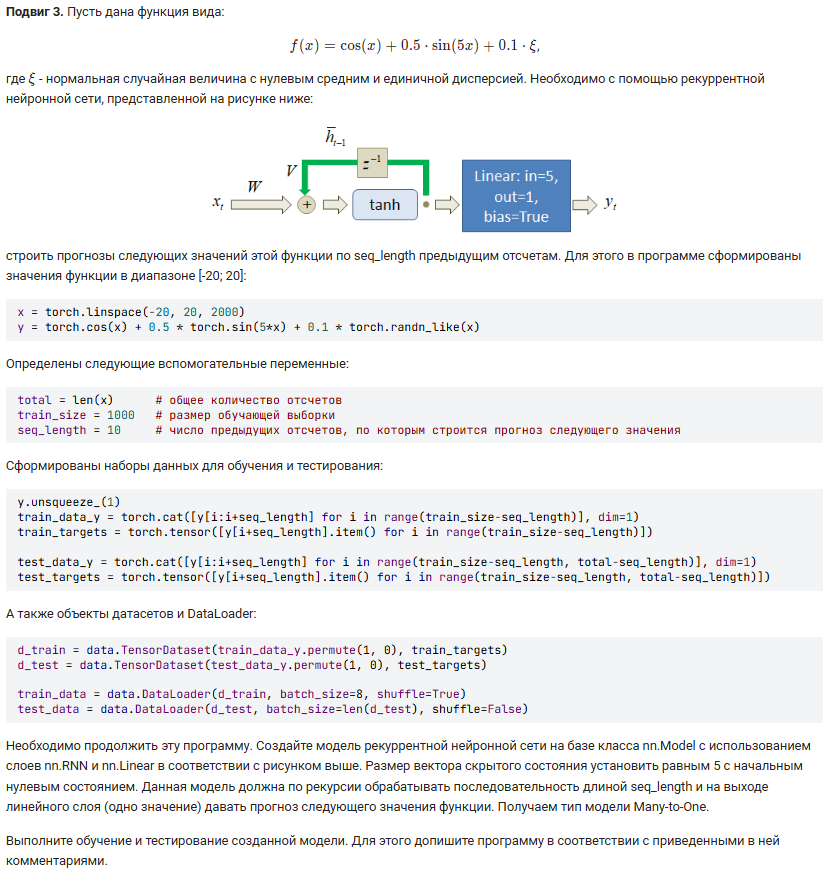

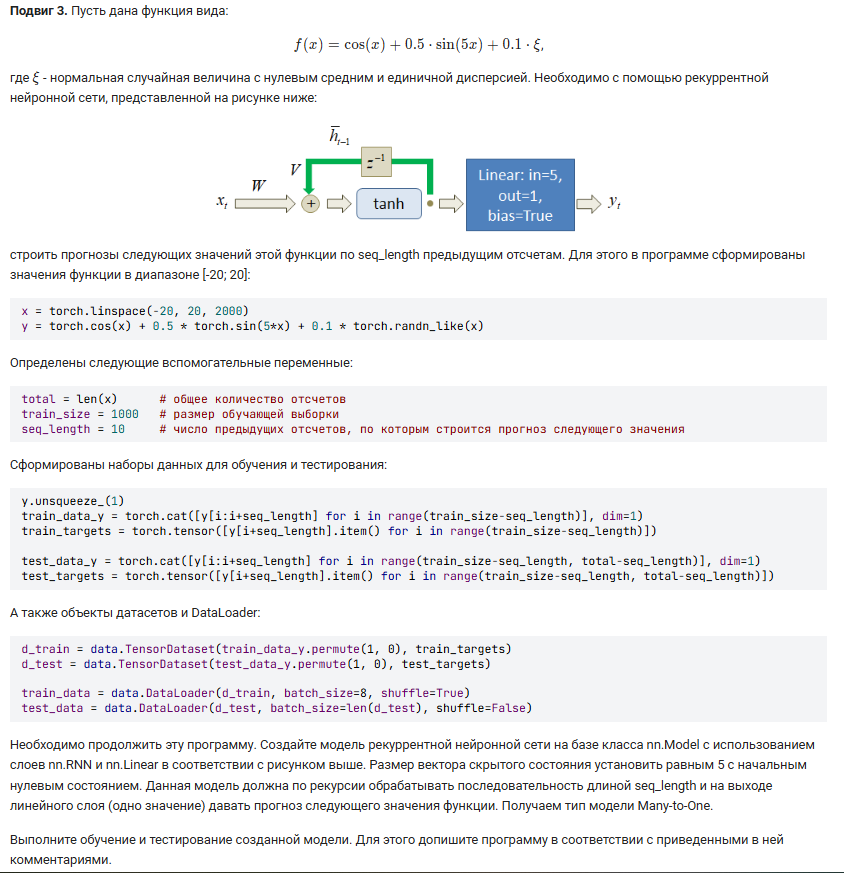

In [87]:
import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim

# здесь объявляйте класс модели
class MyModel(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.rnn = nn.RNN(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, 1, bias=True)
        
    def forward(self, x):
        y, h = self.rnn(x)
        out = self.linear(h)
        # print(out.shape)
        return out[0, :, 0]

x = torch.linspace(-20, 20, 2000)
y = torch.cos(x) + 0.5 * torch.sin(5*x) + 0.1 * torch.randn_like(x)

total = len(x)      # общее количество отсчетов
train_size = 1000   # размер обучающей выборки
seq_length = 10     # число предыдущих отсчетов, по которым строится прогноз следующего значения

y.unsqueeze_(1)
train_data_y = torch.cat([y[i:i+seq_length] for i in range(train_size-seq_length)], dim=1)
train_targets = torch.tensor([y[i+seq_length].item() for i in range(train_size-seq_length)])

test_data_y = torch.cat([y[i:i+seq_length] for i in range(train_size-seq_length, total-seq_length)], dim=1)
test_targets = torch.tensor([y[i+seq_length].item() for i in range(train_size-seq_length, total-seq_length)])

d_train = data.TensorDataset(train_data_y.permute(1, 0), train_targets)
d_test = data.TensorDataset(test_data_y.permute(1, 0), test_targets)

train_data = data.DataLoader(d_train, batch_size=8, shuffle=True)
test_data = data.DataLoader(d_test, batch_size=len(d_test), shuffle=False)

model = MyModel(input_size=1, hidden_size=5) # создание объекта модели

optimizer = optim.RMSprop(model.parameters(), lr=0.001) # оптимизатор RMSprop с шагом обучения 0.001
loss_func = nn.MSELoss()  # функция потерь - средний квадрат ошибок

epochs = 5 # число эпох
# переведите модель в режим обучения
model.train()

for _e in range(epochs):
    for x_train, y_train in train_data:
        # print(x_train.shape)
        predict = model(x_train.unsqueeze(-1)) # вычислите прогноз модели для x_train
        # print(predict.shape, y_train.shape)
        loss = loss_func(predict, y_train) # вычислите потери для predict и y_train

        # выполните один шаг обучения (градиентного спуска)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        

# переведите модель в режим эксплуатации
model.eval()
d, t = next(iter(test_data))
# с использованием менеджера torch.no_grad вычислите прогнозы для выборки d
# результат сохраните в тензоре predict
with torch.no_grad():
    predict = model(d.unsqueeze(-1)).squeeze()
    
Q = loss_func(predict, t).item() # вычислите потери с помощью loss_func для predict и t; значение Q сохраните в виде вещественного числа
Q

0.023361099883913994

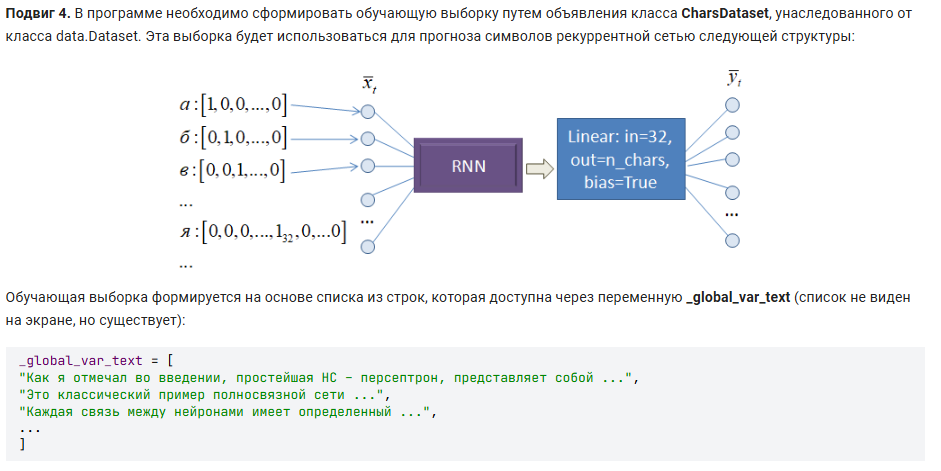

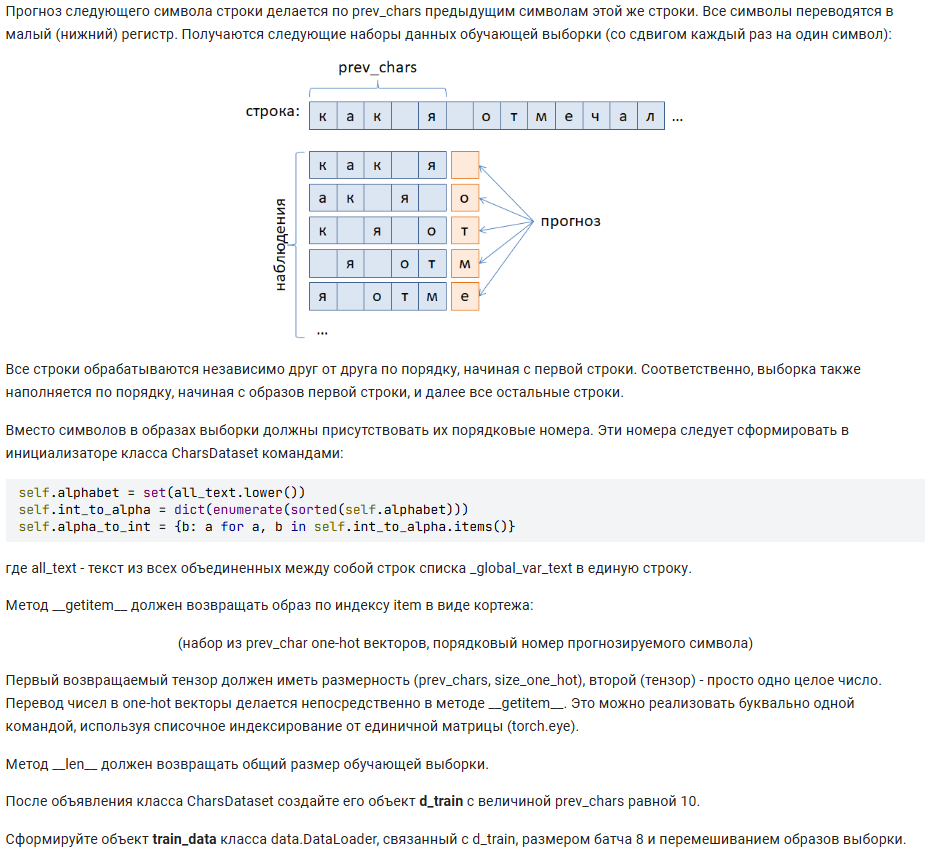

In [103]:
import torch
import torch.nn as nn
import torch.utils.data as data

_global_var_text = [
"Как я отмечал во введении, простейшая НС – персептрон, представляет собой ...",
"Это классический пример полносвязной сети ...",
"Каждая связь между нейронами имеет определенный ..."
]

# здесь объявляйте класс CharsDataset
class CharsDataset(data.Dataset):
    def __init__(self, prev_chars):
        super().__init__()
        self.prev_chars = prev_chars
        self.lines = _global_var_text
        self.all_text = ''.join(_global_var_text)
        self.alphabet = set(self.all_text.lower())
        self.int_to_alpha = dict(enumerate(sorted(self.alphabet)))
        self.alpha_to_int = {b: a for a, b in self.int_to_alpha.items()}
        self.onehots = torch.eye(len(self.alphabet))

        data = []
        targets = []
        for line in self.lines:
            line = line.lower()
            for i in range(prev_chars, len(line)):
                chars = line[i-prev_chars: i] #abc, bcd, cde, def...
                char_numbers = [self.alpha_to_int[char] for char in chars]
                
                target = line[i]
                target_number = self.alpha_to_int[target]
                
                data.append(char_numbers)
                targets.append(target_number)

        self.data = torch.tensor(data)
        self.targets = torch.tensor(targets)

    
    def __getitem__(self, item):
        return (self.onehots[self.data[item]], self.targets[item])
        

    def __len__(self):
        return len(self.data)
        
    
d_train = CharsDataset(10)
train_data = data.DataLoader(d_train, batch_size=8, shuffle=True)


# здесь продолжайте программу

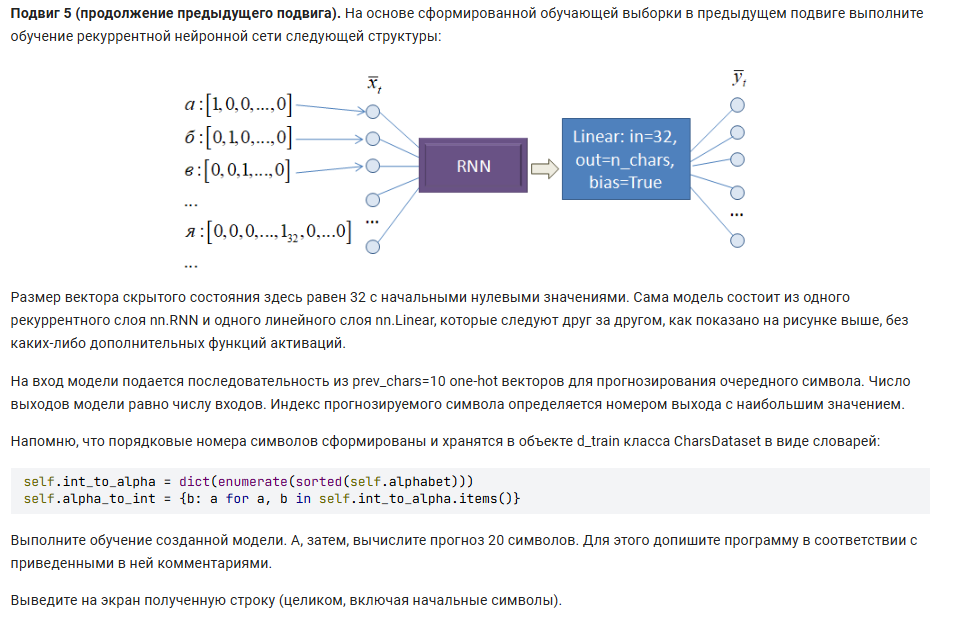

In [193]:
import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim


# сюда копируйте класс CharsDataset из предыдущего подвига
class CharsDataset(data.Dataset):
    def __init__(self, prev_chars):
        super().__init__()
        self.prev_chars = prev_chars
        self.lines = _global_var_text
        self.all_text = ''.join(_global_var_text)
        self.alphabet = set(self.all_text.lower())
        self.alphabet_length = len(self.alphabet)
        self.int_to_alpha = dict(enumerate(sorted(self.alphabet)))
        self.alpha_to_int = {b: a for a, b in self.int_to_alpha.items()}
        self.onehots = torch.eye(len(self.alphabet))

        data = []
        targets = []
        for line in self.lines:
            line = line.lower()
            for i in range(prev_chars, len(line)):
                chars = line[i-prev_chars: i] #abc, bcd, cde, def...
                char_numbers = [self.alpha_to_int[char] for char in chars]
                
                target = line[i]
                target_number = self.alpha_to_int[target]
                
                data.append(char_numbers)
                targets.append(target_number)

        self.data = torch.tensor(data)
        self.targets = torch.tensor(targets)

    
    def __getitem__(self, item):
        return (self.onehots[self.data[item]], self.targets[item])
        

    def __len__(self):
        return len(self.data)


# здесь объявляйте класс модели нейронной сети
class MyNet(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.hidden_size=32
        self.rnn = nn.RNN(input_size=in_features, hidden_size=self.hidden_size, batch_first=True)
        self.linear = nn.Linear(in_features=self.hidden_size, out_features=out_features)

    
    def forward(self, x):
        y, h = self.rnn(x)
        return self.linear(h)
        
        


# сюда копируйте объекты d_train и train_data
d_train = CharsDataset(10)
train_data = data.DataLoader(d_train, batch_size=8, shuffle=True)

model = MyNet(in_features=d_train.alphabet_length, out_features=d_train.alphabet_length) # создайте объект модели

optimizer = optim.Adam(model.parameters(), lr=0.01) # оптимизатор Adam с шагом обучения 0.01
loss_func = nn.CrossEntropyLoss() # функция потерь - CrossEntropyLoss

epochs = 1 # число эпох (это конечно, очень мало, в реальности нужно от 100 и более)
# переведите модель в режим обучения
model.train()

for _e in range(epochs):
    for x_train, y_train in train_data:
        predict = model(x_train).squeeze(0) # вычислите прогноз модели для x_train
        # print(predict.shape, y_train.shape)
        # print(y_train)
        # print(d_train.onehots[y_train])
        # print(predict)
        # print('-----')
        loss = loss_func(predict, y_train) # вычислите потери для predict и y_train
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # выполните один шаг обучения (градиентного спуска)

# переведите модель в режим эксплуатации
model.eval()
predict = "нейронная сеть ".lower() # начальная фраза
total = 20 # число прогнозируемых символов (дополнительно к начальной фразе)

# выполните прогноз следующих total символов

for _ in range(total):
    seq = predict[-d_train.prev_chars: ]
    one_hot_seq = d_train.onehots[[d_train.alpha_to_int[letter] for letter in seq]]
    with torch.no_grad():
        pred = model(one_hot_seq.unsqueeze(0)).squeeze(0)
    indx = torch.argmax(pred, dim=1).item()
    pred_letter = d_train.int_to_alpha[indx]
    predict += pred_letter

# one_hot_seq = d_train.onehots[[d_train.alpha_to_int[letter] for letter in predict]]
# with torch.no_grad():
#     pred = model(one_hot_seq.unsqueeze(0)).squeeze(0)
# indx = torch.argmax(pred, dim=1).item()
# pred_letter = d_train.int_to_alpha[indx]
# predict += pred_letter
# # print(pred_letter)

# for _ in range(total-1):
#     one_hot = d_train.onehots[[d_train.alpha_to_int[pred_letter]]]
#     with torch.no_grad():
#         pred = model(one_hot.unsqueeze(0)).squeeze(0)
#     indx = torch.argmax(pred, dim=1).item()
#     pred_letter = d_train.int_to_alpha[indx]
#     predict += pred_letter
#     # print(pred_letter)
    
    

    
# выведите полученную строку на экран
print(predict)

35 нейронная сеть ееееееееееееееееееее


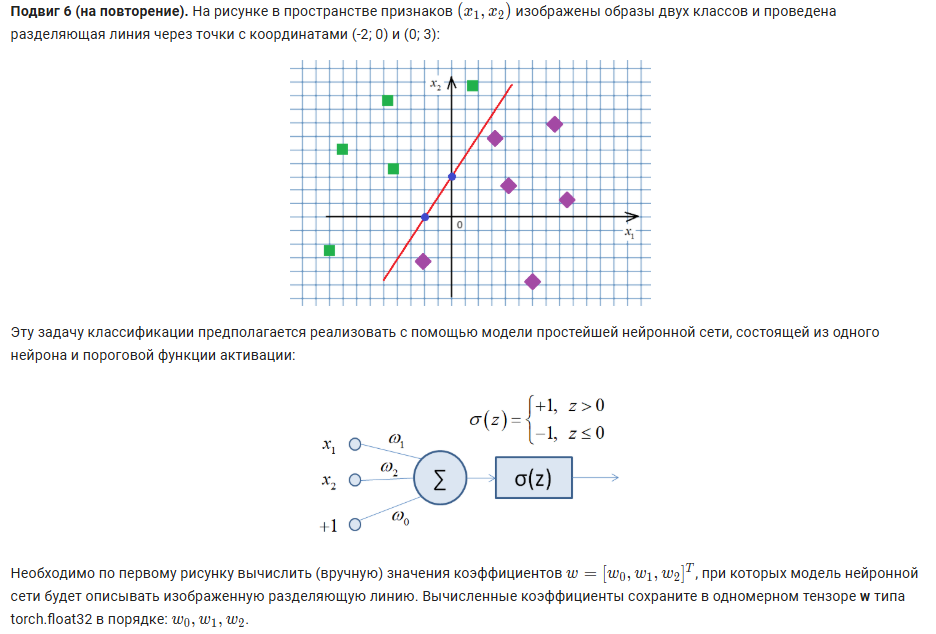

In [ ]:
import torch

w = torch.tensor([6, 3, -2], dtype=torch.float32)